# FINTRACE — Peti eksperiment

## Ablacija karakteristika, predobrada i optimizacija modela

Cilj je analizirati utjecaj odabira ulaznih karakteristika, transformacija numeričkih vrijednosti i hiperparametara na XGBoost, MLP i GraphSAGE, uz hronološku evaluaciju.

- **Faza A:** grupna ablacija svih 182 karakteristike, uključujući PCA.
- **Faza B:** poređenje alternativnih postupaka predobrade.
- **Faza C.1:** kombinovanje najperspektivnijih skupova karakteristika i predobrade.
- **Faza C.2:** stabilnost na seed vrijednostima 42, 123 i 2026.
- **Faza C.3:** ciljano podešavanje hiperparametara, također na tri seeda.
- **Faza C.4:** završno poređenje unaprijed odabranih modela na koracima 42–49.

**Razvojni odabir** koristi samo korake 1–41. Period 42–49 koristi se za naknadno poređenje s ranijim rezultatima; već je bio analiziran u prethodnom eksperimentu, pa nije potpuno netaknut na nivou istraživačkog postupka.


In [ ]:

from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import os
import sys

PROJECT_DIR = Path(
    '/content/drive/MyDrive/fingraph-ai/'
    'FinGraph_AI_MPVI_Starter'
)

assert PROJECT_DIR.is_dir(), (
    f"Projekt nije pronađen: {PROJECT_DIR}"
)

os.chdir(PROJECT_DIR)
sys.path.insert(0, str(PROJECT_DIR / "src"))

assert (
    PROJECT_DIR / "src/fingraph/phase05.py"
).is_file(), "Nedostaje phase05.py"

assert (
    PROJECT_DIR / "data/raw/txs_features.csv"
).is_file(), "Nedostaju Elliptic++ podaci"

print("Projektni folder:", PROJECT_DIR)


Mounted at /content/drive
Projektni folder: /content/drive/MyDrive/fingraph-ai/FinGraph_AI_MPVI_Starter


In [ ]:

%pip install -q -e .

# Potrebno za GraphSAGE ako nije instalirano:
%pip install -q torch-geometric


  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for fingraph-ai-mpvi (pyproject.toml) ... done


In [ ]:

import json
import zipfile
import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from fingraph.data import load_elliptic

from fingraph.phase05 import (
    FOLDS,
    FEATURE_VARIANTS,
    PREPROCESS_VARIANTS,
    BASE_CONFIG,
    TUNING_CONFIGS,
    fit_processor,
    run_one,
    summary_table,
    selection_table,
)

SEED = 42

OUT = PROJECT_DIR / "outputs/phase05"
TABLES = OUT / "tables"
FIGURES = OUT / "figures"

for folder in (TABLES, FIGURES):
    folder.mkdir(parents=True, exist_ok=True)

graph = load_elliptic(PROJECT_DIR / "data/raw")

print("Čvorovi:", graph.num_nodes)
print("Veze:", graph.num_edges)
print("Broj karakteristika:", len(graph.feature_names))
print("Hronološke podjele:", FOLDS)

print(
    "Lokalne karakteristike:",
    sum(
        name.startswith("Local_feature_")
        for name in graph.feature_names
    )
)

print(
    "Agregirane karakteristike:",
    sum(
        name.startswith("Aggregate_feature_")
        for name in graph.feature_names
    )
)


Čvorovi: 203769
Veze: 234355
Broj karakteristika: 182
Hronološke podjele: {'A': (20, 27), 'B': (27, 34), 'C': (34, 41)}
Lokalne karakteristike: 93
Agregirane karakteristike: 72


In [ ]:

from fingraph.phase05 import feature_indices

audit_rows = []

for variant in FEATURE_VARIANTS:

    indices = feature_indices(
        graph.feature_names,
        variant,
    )

    for index in indices:

        audit_rows.append({
            "variant": variant,
            "feature_index": int(index),
            "feature_name": graph.feature_names[index],
        })

feature_audit = pd.DataFrame(audit_rows)

feature_audit.to_csv(
    TABLES / "phase05_feature_selection_audit.csv",
    index=False,
)

display(
    feature_audit.groupby("variant")
    .size()
    .rename("Broj karakteristika")
)

print("Sačuvan popis odabranih karakteristika.")


,Broj karakteristika
variant,
aggregate_only,72
all,182
all_pca95,182
local_only,93
named_only,17
without_aggregate,110


Sačuvan popis odabranih karakteristika.


## Konfiguracija faza A i B

Prekidači `RUN_ABLATION` i `RUN_PREPROCESSING` upravljaju prethodnim fazama. `RUN_TUNING` je starija kontrolna varijabla iz početne verzije notebooka; **stvarna faza C.3** pokreće se kasnijom funkcijom `run_tuning()` iz `phase05_stage_C.py`.

Kada su A i B već završene, prekidače ostavi isključene. `SKIP_EXISTING=True` koristi se da se sačuvani pokušaji ne ponavljaju.


In [ ]:

RUN_ABLATION = False
RUN_PREPROCESSING = False
RUN_TUNING = True

MODELS_TO_RUN = [
    "XGBoost",
    "MLP",
    "GraphSAGE",
]

FOLDS_TO_RUN = ["A", "B", "C"]

SKIP_EXISTING = True

TUNING_FEATURE_VARIANT = "all"
TUNING_PREPROCESS = "median_standard"



## Provjera hronoloških podjela i PCA

Koriste se tri razvojne podjele:

| Podjela | Trening | Validacija |
|---|---|---|
| A | 1–20 | 21–27 |
| B | 1–27 | 28–34 |
| C | 1–34 | 35–41 |

Imputacija, skaliranje i PCA prilagođavaju se isključivo podacima iz odgovarajućeg trening perioda.

Neoznačene transakcije iz trening perioda mogu se koristiti za procjenu distribucije karakteristika, ali se ne tretiraju kao negativna klasa.


In [ ]:

from fingraph.phase05 import masks

rows = []

for fold, (train_end, valid_end) in FOLDS.items():

    train_mask, valid_mask = masks(
        graph, train_end, valid_end
    )

    processor = fit_processor(
        graph,
        train_end,
        "all_pca95",
        "median_standard",
    )

    rows.append({
        "fold": fold,
        "train": f"1-{train_end}",
        "validation": f"{train_end + 1}-{valid_end}",
        "train_labeled": int(train_mask.sum()),
        "validation_labeled": int(valid_mask.sum()),
        "validation_positives": int(
            (graph.labels[valid_mask] == 1).sum()
        ),
        "validation_positive_rate": float(
            (graph.labels[valid_mask] == 1).mean()
        ),
        "preprocessing_fit_nodes": processor.fit_count,
        "pca_components_95": processor.n_features,
        "pca_retained_variance": float(
            sum(processor.pca.explained_variance_ratio_)
        ),
    })

fold_table = pd.DataFrame(rows)

display(fold_table)

fold_table.to_csv(
    TABLES / "phase05_fold_and_pca_audit.csv",
    index=False,
)


,fold,train,validation,train_labeled,validation_labeled,validation_positives,validation_positive_rate,preprocessing_fit_nodes,pca_components_95,pca_retained_variance
0,A,1-20,21-27,18889,6034,686,0.113689,90762,61,0.952820
1,B,1-27,28-34,24923,4971,1005,0.202173,114876,60,0.951248
2,C,1-34,35-41,29894,7829,675,0.086218,136265,60,0.950478


## Faza A — Ablacijska analiza karakteristika

Ispituje se **šest** varijanti:

1. `all` — svih 182 karakteristike.
2. `without_aggregate` — bez 72 agregirane karakteristike (110 ulaza).
3. `local_only` — 93 lokalne karakteristike.
4. `aggregate_only` — 72 agregirane karakteristike.
5. `named_only` — 17 imenovanih karakteristika.
6. `all_pca95` — glavne komponente koje objašnjavaju najmanje 95% varijanse.

U ovoj fazi koristi se `median_standard` i početna konfiguracija svakog modela. PCA ne isključuje pojedine originalne grupe karakteristika, nego ih linearno kombinuje.


In [ ]:

if RUN_ABLATION:

    for model in MODELS_TO_RUN:

        for feature_variant in FEATURE_VARIANTS:

            for fold in FOLDS_TO_RUN:

                print(
                    "ABLACIJA:",
                    model,
                    feature_variant,
                    fold,
                    flush=True,
                )

                result = run_one(
                    graph,
                    OUT,
                    stage="ablation",
                    model_name=model,
                    fold_name=fold,
                    feature_variant=feature_variant,
                    preprocess="median_standard",
                    seed=SEED,
                    skip_existing=SKIP_EXISTING,
                )

                print(
                    "PR-AUC:",
                    round(result["pr_auc"], 4),
                    "Broj ulaza:",
                    result["n_inputs"],
                )

else:
    print("Ablacija nije uključena.")


ABLACIJA: XGBoost all A
PR-AUC: 0.8634 Broj ulaza: 182
ABLACIJA: XGBoost all B
PR-AUC: 0.9836 Broj ulaza: 182
ABLACIJA: XGBoost all C
PR-AUC: 0.9357 Broj ulaza: 182
ABLACIJA: XGBoost without_aggregate A
PR-AUC: 0.8519 Broj ulaza: 110
ABLACIJA: XGBoost without_aggregate B
PR-AUC: 0.9814 Broj ulaza: 110
ABLACIJA: XGBoost without_aggregate C
PR-AUC: 0.9244 Broj ulaza: 110
ABLACIJA: XGBoost local_only A
PR-AUC: 0.8562 Broj ulaza: 93
ABLACIJA: XGBoost local_only B
PR-AUC: 0.9836 Broj ulaza: 93
ABLACIJA: XGBoost local_only C
PR-AUC: 0.9285 Broj ulaza: 93
ABLACIJA: XGBoost aggregate_only A
PR-AUC: 0.8176 Broj ulaza: 72
ABLACIJA: XGBoost aggregate_only B
PR-AUC: 0.8611 Broj ulaza: 72
ABLACIJA: XGBoost aggregate_only C
PR-AUC: 0.7909 Broj ulaza: 72
ABLACIJA: XGBoost named_only A
PR-AUC: 0.734 Broj ulaza: 17
ABLACIJA: XGBoost named_only B
PR-AUC: 0.5092 Broj ulaza: 17
ABLACIJA: XGBoost named_only C
PR-AUC: 0.7315 Broj ulaza: 17
ABLACIJA: XGBoost all_pca95 A
PR-AUC: 0.7809 Broj ulaza: 61
ABLACIJA

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


PR-AUC: 0.6321 Broj ulaza: 182
ABLACIJA: GraphSAGE all B
PR-AUC: 0.8315 Broj ulaza: 182
ABLACIJA: GraphSAGE all C
PR-AUC: 0.5384 Broj ulaza: 182
ABLACIJA: GraphSAGE without_aggregate A
PR-AUC: 0.5557 Broj ulaza: 110
ABLACIJA: GraphSAGE without_aggregate B
PR-AUC: 0.7789 Broj ulaza: 110
ABLACIJA: GraphSAGE without_aggregate C
PR-AUC: 0.6083 Broj ulaza: 110
ABLACIJA: GraphSAGE local_only A
PR-AUC: 0.617 Broj ulaza: 93
ABLACIJA: GraphSAGE local_only B
PR-AUC: 0.7446 Broj ulaza: 93
ABLACIJA: GraphSAGE local_only C
PR-AUC: 0.5371 Broj ulaza: 93
ABLACIJA: GraphSAGE aggregate_only A
PR-AUC: 0.4491 Broj ulaza: 72
ABLACIJA: GraphSAGE aggregate_only B
PR-AUC: 0.7079 Broj ulaza: 72
ABLACIJA: GraphSAGE aggregate_only C
PR-AUC: 0.3037 Broj ulaza: 72
ABLACIJA: GraphSAGE named_only A
PR-AUC: 0.212 Broj ulaza: 17
ABLACIJA: GraphSAGE named_only B
PR-AUC: 0.4732 Broj ulaza: 17
ABLACIJA: GraphSAGE named_only C
PR-AUC: 0.1527 Broj ulaza: 17
ABLACIJA: GraphSAGE all_pca95 A
PR-AUC: 0.6609 Broj ulaza: 61
ABL

,model,feature_variant,preprocess,config_id,folds,mean_pr_auc,worst_pr_auc,std_pr_auc,mean_ap_lift,mean_f1
1,GraphSAGE,all,median_standard,baseline,3,0.667344,0.538431,0.149698,5.305879,0.628531
5,GraphSAGE,without_aggregate,median_standard,baseline,3,0.647636,0.555745,0.116647,5.265373,0.631234
2,GraphSAGE,all_pca95,median_standard,baseline,3,0.644699,0.547288,0.090424,5.250435,0.614921
3,GraphSAGE,local_only,median_standard,baseline,3,0.632902,0.537090,0.104649,5.113249,0.610868
0,GraphSAGE,aggregate_only,median_standard,baseline,3,0.486920,0.303723,0.204729,3.658238,0.504866
4,GraphSAGE,named_only,median_standard,baseline,3,0.279298,0.152738,0.170502,1.992171,0.354750
11,MLP,without_aggregate,median_standard,baseline,3,0.807861,0.733017,0.077841,6.715285,0.787802
9,MLP,local_only,median_standard,baseline,3,0.710186,0.617315,0.130426,6.210337,0.717356
7,MLP,all,median_standard,baseline,3,0.696007,0.664833,0.032310,5.913025,0.663681
8,MLP,all_pca95,median_standard,baseline,3,0.683898,0.645183,0.033996,5.782528,0.646909


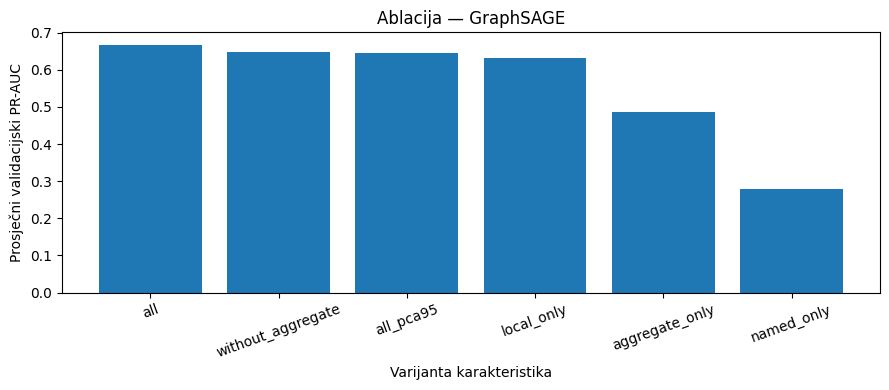

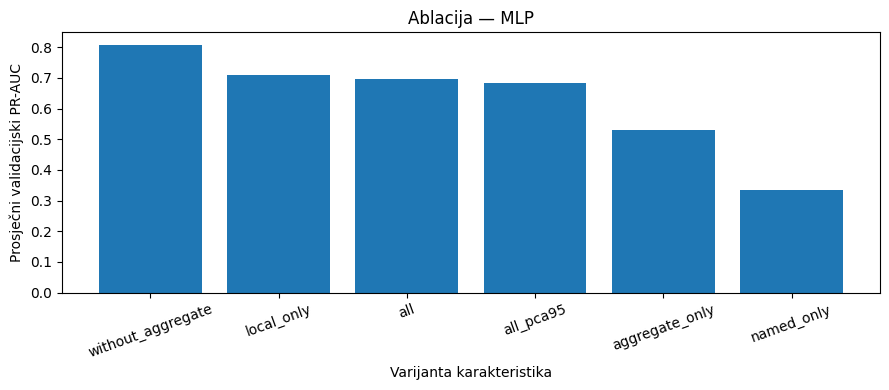

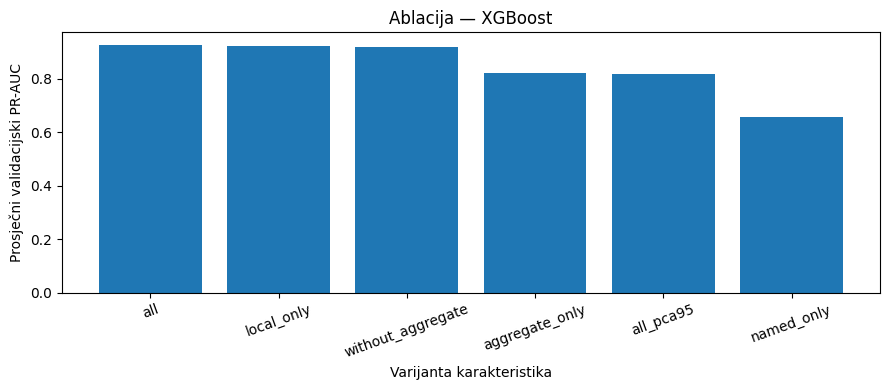

In [ ]:

summary = summary_table(OUT)

if not summary.empty:

    summary.to_csv(
        TABLES / "phase05_all_runs_summary.csv",
        index=False,
    )

    ablation = selection_table(
        summary, "ablation"
    )

    if not ablation.empty:

        ablation.to_csv(
            TABLES / "phase05_ablation_comparison.csv",
            index=False,
        )

        display(ablation)

        for model, subset in ablation.groupby("model"):

            fig, ax = plt.subplots(figsize=(9, 4))

            ax.bar(
                subset["feature_variant"],
                subset["mean_pr_auc"],
            )

            ax.set_title(f"Ablacija — {model}")
            ax.set_ylabel("Prosječni validacijski PR-AUC")
            ax.set_xlabel("Varijanta karakteristika")

            ax.tick_params(
                axis="x", rotation=20
            )

            fig.tight_layout()

            fig.savefig(
                FIGURES
                / f"phase05_ablation_{model.lower()}.png",
                dpi=160,
            )

            plt.show()

else:
    print("Još nema završenih treniranja.")


## Faza B — Alternativna predobrada

Uz svih 182 karakteristike i nepromijenjene hiperparametre testirane su **četiri nove** metode:

- `median_robust` — medijanska imputacija + RobustScaler.
- `median_log_robust` — selektivna log1p transformacija + RobustScaler.
- `median_quantile` — medijanska imputacija + QuantileTransformer (normalni izlaz).
- `median_power` — medijanska imputacija + Yeo–Johnson PowerTransformer.

Referenca je `median_standard` iz faze A. Svaka nova metoda evaluirana je na sve tri razvojne podjele za sva tri modela (36 treniranja). Najveće poboljšanje neuronskih modela ostvareno je uz kvantilsku transformaciju, što je određivalo izbor kandidata u fazi C.


In [ ]:

if RUN_PREPROCESSING:

    for model in MODELS_TO_RUN:

        for preprocess in PREPROCESS_VARIANTS:

            for fold in FOLDS_TO_RUN:

                print(
                    "PREPROCESSING:",
                    model,
                    preprocess,
                    fold,
                    flush=True,
                )

                result = run_one(
                    graph,
                    OUT,
                    stage="preprocessing",
                    model_name=model,
                    fold_name=fold,
                    feature_variant="all",
                    preprocess=preprocess,
                    seed=SEED,
                    skip_existing=SKIP_EXISTING,
                )

                print(
                    "PR-AUC:",
                    round(result["pr_auc"], 4),
                )

else:
    print("Preprocessing faza nije uključena.")


PREPROCESSING: XGBoost median_robust A
PR-AUC: 0.8636
PREPROCESSING: XGBoost median_robust B
PR-AUC: 0.9859
PREPROCESSING: XGBoost median_robust C
PR-AUC: 0.9361
PREPROCESSING: XGBoost median_log_robust A
PR-AUC: 0.8647
PREPROCESSING: XGBoost median_log_robust B
PR-AUC: 0.9849
PREPROCESSING: XGBoost median_log_robust C
PR-AUC: 0.9344
PREPROCESSING: XGBoost median_quantile A
PR-AUC: 0.8654
PREPROCESSING: XGBoost median_quantile B
PR-AUC: 0.9848
PREPROCESSING: XGBoost median_quantile C
PR-AUC: 0.9335
PREPROCESSING: XGBoost median_power A
PR-AUC: 0.8684
PREPROCESSING: XGBoost median_power B
PR-AUC: 0.9858
PREPROCESSING: XGBoost median_power C
PR-AUC: 0.9341
PREPROCESSING: MLP median_robust A
PR-AUC: 0.6054
PREPROCESSING: MLP median_robust B
PR-AUC: 0.8236
PREPROCESSING: MLP median_robust C
PR-AUC: 0.5033
PREPROCESSING: MLP median_log_robust A
PR-AUC: 0.6037
PREPROCESSING: MLP median_log_robust B
PR-AUC: 0.823
PREPROCESSING: MLP median_log_robust C
PR-AUC: 0.4998
PREPROCESSING: MLP median_

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


PR-AUC: 0.2292
PREPROCESSING: GraphSAGE median_robust B
PR-AUC: 0.5596
PREPROCESSING: GraphSAGE median_robust C
PR-AUC: 0.1537
PREPROCESSING: GraphSAGE median_log_robust A
PR-AUC: 0.2303
PREPROCESSING: GraphSAGE median_log_robust B
PR-AUC: 0.5731
PREPROCESSING: GraphSAGE median_log_robust C
PR-AUC: 0.1531
PREPROCESSING: GraphSAGE median_quantile A
PR-AUC: 0.8172
PREPROCESSING: GraphSAGE median_quantile B
PR-AUC: 0.859
PREPROCESSING: GraphSAGE median_quantile C
PR-AUC: 0.8999
PREPROCESSING: GraphSAGE median_power A
PR-AUC: 0.7974
PREPROCESSING: GraphSAGE median_power B
PR-AUC: 0.8517
PREPROCESSING: GraphSAGE median_power C
PR-AUC: 0.8661


In [ ]:

summary = summary_table(OUT)

if not summary.empty:

    preprocessing = selection_table(
        summary,
        "preprocessing",
    )

    if not preprocessing.empty:

        preprocessing.to_csv(
            TABLES / "phase05_preprocessing_comparison.csv",
            index=False,
        )

        display(preprocessing)

    else:
        print("Još nema preprocessing rezultata.")


,model,feature_variant,preprocess,config_id,folds,mean_pr_auc,worst_pr_auc,std_pr_auc,mean_ap_lift,mean_f1
2,GraphSAGE,all,median_quantile,baseline,3,0.858724,0.817230,0.041359,7.291718,0.804604
1,GraphSAGE,all,median_power,baseline,3,0.838421,0.797435,0.036214,7.090826,0.770754
0,GraphSAGE,all,median_log_robust,baseline,3,0.318860,0.153106,0.223566,2.212245,0.383649
3,GraphSAGE,all,median_robust,baseline,3,0.314154,0.153714,0.215853,2.188835,0.369856
6,MLP,all,median_quantile,baseline,3,0.902964,0.849138,0.048221,7.590484,0.858970
5,MLP,all,median_power,baseline,3,0.865413,0.820573,0.064660,7.187597,0.804346
7,MLP,all,median_robust,baseline,3,0.644133,0.503328,0.163628,5.079034,0.634099
4,MLP,all,median_log_robust,baseline,3,0.642138,0.499753,0.165015,5.058994,0.630621
9,XGBoost,all,median_power,baseline,3,0.929438,0.868441,0.058814,7.782891,0.908417
11,XGBoost,all,median_robust,baseline,3,0.928523,0.863564,0.061512,7.776639,0.911856


## Faza C — Kombinovanje konfiguracija, stabilnost i ciljani tuning

Za C.1 biraju se tri konfiguracije po modelu na osnovu rezultata faza A i B, ukupno devet kandidata. C.2 ponavlja te konfiguracije na seed vrijednostima `42`, `123` i `2026`, uz tri razvojna folda (ukupno 81 treniranje za C.1/C.2).

U C.3 biraju se početni kandidati `xgb_all_standard`, `mlp_all_quantile` i `sage_all_quantile`, pa se testiraju četiri ciljane promjene hiperparametara za svaki model. Svaka promjena evaluirana je na sva tri folda i sva tri seeda (108 treniranja). Evaluacija uključuje upareno poređenje s početnim modelom pri istom foldu i seedu.

Tuning se zasniva na koracima 1–41; testni koraci 42–49 nisu dio izbora hiperparametara.


In [ ]:

import importlib
import pandas as pd

import fingraph.phase05 as phase05
import fingraph.phase05_stage_C as phase05_c

# Korisno ako si mijenjala fajlove dok je Colab otvoren.
importlib.reload(phase05)
importlib.reload(phase05_c)

from fingraph.phase05_stage_C import (
    CANDIDATES,
    TUNING,
    run_screening,
    run_tuning,
    run_confirmation,
    report,
)

print("Broj kandidata:", len(CANDIDATES))
print("Modeli:", list(TUNING.keys()))
print("Izlazni folder:", OUT)

assert len(CANDIDATES) == 9
assert OUT.exists()


Broj kandidata: 9
Modeli: ['XGBoost', 'MLP', 'GraphSAGE']
Izlazni folder: /content/drive/MyDrive/fingraph-ai/FinGraph_AI_MPVI_Starter/outputs/phase05


In [ ]:

# Faza C — kontrolne varijable

RUN_C1_COMBINATIONS = True
RUN_C2_SEED_STABILITY = False
RUN_C3_TUNING = False


SEED_BASELINE = 42
ADDITIONAL_SEEDS = [123, 2026]

FOLDS_C = ["A", "B", "C"]

print("Kombinacije:", RUN_C1_COMBINATIONS)
print("Seed stabilnost:", RUN_C2_SEED_STABILITY)
print("Tuning:", RUN_C3_TUNING)
print("Potvrda:", RUN_C4_CONFIRMATION)


Kombinacije: True
Seed stabilnost: False
Tuning: False
Potvrda: False


In [ ]:

if RUN_C1_COMBINATIONS:

    run_screening(
        graph,
        OUT,
        seeds=[SEED_BASELINE],
        folds=FOLDS_C,
    )

else:
    print("C.1 nije uključena.")


SCREENING xgb_all_standard A 42
PR-AUC: 0.8634
SCREENING xgb_all_standard B 42
PR-AUC: 0.9836
SCREENING xgb_all_standard C 42
PR-AUC: 0.9357
SCREENING xgb_all_power A 42
PR-AUC: 0.8684
SCREENING xgb_all_power B 42
PR-AUC: 0.9858
SCREENING xgb_all_power C 42
PR-AUC: 0.9341
SCREENING xgb_local_standard A 42
PR-AUC: 0.8562
SCREENING xgb_local_standard B 42
PR-AUC: 0.9836
SCREENING xgb_local_standard C 42
PR-AUC: 0.9285
SCREENING mlp_all_quantile A 42
PR-AUC: 0.8491
SCREENING mlp_all_quantile B 42
PR-AUC: 0.9422
SCREENING mlp_all_quantile C 42
PR-AUC: 0.9175
SCREENING mlp_noaggregate_quantile A 42
PR-AUC: 0.8265
SCREENING mlp_noaggregate_quantile B 42
PR-AUC: 0.9278
SCREENING mlp_noaggregate_quantile C 42
PR-AUC: 0.9126
SCREENING mlp_local_quantile A 42
PR-AUC: 0.8244
SCREENING mlp_local_quantile B 42
PR-AUC: 0.9355
SCREENING mlp_local_quantile C 42
PR-AUC: 0.915
SCREENING sage_all_quantile A 42


/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


PR-AUC: 0.8172
SCREENING sage_all_quantile B 42
PR-AUC: 0.859
SCREENING sage_all_quantile C 42
PR-AUC: 0.8999
SCREENING sage_noaggregate_quantile A 42
PR-AUC: 0.8177
SCREENING sage_noaggregate_quantile B 42
PR-AUC: 0.9131
SCREENING sage_noaggregate_quantile C 42
PR-AUC: 0.8957
SCREENING sage_local_quantile A 42
PR-AUC: 0.8065
SCREENING sage_local_quantile B 42
PR-AUC: 0.9179
SCREENING sage_local_quantile C 42
PR-AUC: 0.8916


In [ ]:

comparison = report(OUT)

if not comparison.empty:

    screening = comparison[
        comparison["phase"] == "screening"
    ].copy()

    display(screening)

    print("\nNajbolji kandidati po modelu:")

    best_candidates = (
        screening.sort_values(
            ["model", "mean_pr_auc"],
            ascending=[True, False],
        )
        .groupby("model")
        .head(1)
    )

    display(best_candidates)


Completed runs: {'screening': 27}


,phase,model,candidate,n_folds,mean_pr_auc,worst_fold_mean,sd_between_folds,mean_sd_between_seeds
2,screening,GraphSAGE,sage_noaggregate_quantile,3,0.875477,0.817711,0.050778,NaN
1,screening,GraphSAGE,sage_local_quantile,3,0.872020,0.806538,0.058208,NaN
0,screening,GraphSAGE,sage_all_quantile,3,0.858724,0.817230,0.041359,NaN
3,screening,MLP,mlp_all_quantile,3,0.902964,0.849138,0.048221,NaN
4,screening,MLP,mlp_local_quantile,3,0.891631,0.824357,0.059151,NaN
5,screening,MLP,mlp_noaggregate_quantile,3,0.888940,0.826461,0.054640,NaN
6,screening,XGBoost,xgb_all_power,3,0.929438,0.868441,0.058814,NaN
7,screening,XGBoost,xgb_all_standard,3,0.927591,0.863447,0.060497,NaN
8,screening,XGBoost,xgb_local_standard,3,0.922794,0.856239,0.063889,NaN



Najbolji kandidati po modelu:


,phase,model,candidate,n_folds,mean_pr_auc,worst_fold_mean,sd_between_folds,mean_sd_between_seeds
2,screening,GraphSAGE,sage_noaggregate_quantile,3,0.875477,0.817711,0.050778,NaN
3,screening,MLP,mlp_all_quantile,3,0.902964,0.849138,0.048221,NaN
6,screening,XGBoost,xgb_all_power,3,0.929438,0.868441,0.058814,NaN


In [ ]:

RUN_C1_COMBINATIONS = False
RUN_C2_SEED_STABILITY = True
RUN_C3_TUNING = False



In [ ]:

if RUN_C2_SEED_STABILITY:

    run_screening(
        graph,
        OUT,
        seeds=ADDITIONAL_SEEDS,
        folds=FOLDS_C,
    )

else:
    print("C.2 nije uključena.")


SCREENING xgb_all_standard A 123
PR-AUC: 0.8613
SCREENING xgb_all_standard A 2026


/content/drive/MyDrive/fingraph-ai/FinGraph_AI_MPVI_Starter/src/fingraph/phase05_stage_C.py:172: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat(


PR-AUC: 0.8626
SCREENING xgb_all_standard B 123


/content/drive/MyDrive/fingraph-ai/FinGraph_AI_MPVI_Starter/src/fingraph/phase05_stage_C.py:172: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat(


PR-AUC: 0.9856
SCREENING xgb_all_standard B 2026


/content/drive/MyDrive/fingraph-ai/FinGraph_AI_MPVI_Starter/src/fingraph/phase05_stage_C.py:172: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat(


... (27 outputs left out)

/content/drive/MyDrive/fingraph-ai/FinGraph_AI_MPVI_Starter/src/fingraph/phase05_stage_C.py:172: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat(


PR-AUC: 0.9268
SCREENING mlp_all_quantile A 123


/content/drive/MyDrive/fingraph-ai/FinGraph_AI_MPVI_Starter/src/fingraph/phase05_stage_C.py:172: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat(


PR-AUC: 0.8545
SCREENING mlp_all_quantile A 2026
PR-AUC: 0.8502
SCREENING mlp_all_quantile B 123
PR-AUC: 0.9403
SCREENING mlp_all_quantile B 2026
PR-AUC: 0.9491
SCREENING mlp_all_quantile C 123
PR-AUC: 0.9146
SCREENING mlp_all_quantile C 2026
PR-AUC: 0.9127
SCREENING mlp_noaggregate_quantile A 123
PR-AUC: 0.8305
SCREENING mlp_noaggregate_quantile A 2026
PR-AUC: 0.8276
SCREENING mlp_noaggregate_quantile B 123
PR-AUC: 0.9305
SCREENING mlp_noaggregate_quantile B 2026
PR-AUC: 0.9303
SCREENING mlp_noaggregate_quantile C 123
PR-AUC: 0.9099
SCREENING mlp_noaggregate_quantile C 2026
PR-AUC: 0.9134
SCREENING mlp_local_quantile A 123
PR-AUC: 0.8257
SCREENING mlp_local_quantile A 2026
PR-AUC: 0.8249
SCREENING mlp_local_quantile B 123
PR-AUC: 0.9396
SCREENING mlp_local_quantile B 2026
PR-AUC: 0.9365
SCREENING mlp_local_quantile C 123
PR-AUC: 0.9143
SCREENING mlp_local_quantile C 2026
PR-AUC: 0.9148
SCREENING sage_all_quantile A 123
PR-AUC: 0.8152
SCREENING sage_all_quantile A 2026
PR-AUC: 0.8237
S

In [ ]:

comparison = report(OUT)

screening = comparison[
    comparison["phase"] == "screening"
].copy()

display(
    screening[
        [
            "model",
            "candidate",
            "n_folds",
            "mean_pr_auc",
            "worst_fold_mean",
            "sd_between_folds",
            "mean_sd_between_seeds",
        ]
    ]
)

registry = pd.read_csv(
    OUT / "tables" / "phase05_c_registry.csv"
)

screening_runs = registry[
    registry["phase"] == "screening"
]

completeness = (
    screening_runs.groupby(
        ["model", "candidate", "fold"]
    )["seed"]
    .nunique()
    .reset_index(name="n_seeds")
)

display(completeness)

assert len(completeness) == 27
assert (completeness["n_seeds"] == 3).all(), (
    "Nedostaju rezultati za neki seed ili fold."
)

print("Svi kandidati imaju tri seed vrijednosti.")


Completed runs: {'screening': 81}


,model,candidate,n_folds,mean_pr_auc,worst_fold_mean,sd_between_folds,mean_sd_between_seeds
0,GraphSAGE,sage_all_quantile,3,0.874687,0.818702,0.048535,0.015939
1,GraphSAGE,sage_local_quantile,3,0.867029,0.804265,0.055151,0.006153
2,GraphSAGE,sage_noaggregate_quantile,3,0.862128,0.805858,0.049143,0.017418
3,MLP,mlp_all_quantile,3,0.903380,0.851299,0.047367,0.003290
4,MLP,mlp_local_quantile,3,0.892308,0.824970,0.059392,0.001066
5,MLP,mlp_noaggregate_quantile,3,0.889892,0.828192,0.054152,0.001802
6,XGBoost,xgb_all_power,3,0.928524,0.865151,0.060678,0.001174
7,XGBoost,xgb_all_standard,3,0.927728,0.862447,0.061822,0.001011
8,XGBoost,xgb_local_standard,3,0.922040,0.856817,0.062974,0.001510


,model,candidate,fold,n_seeds
0,GraphSAGE,sage_all_quantile,A,3
1,GraphSAGE,sage_all_quantile,B,3
2,GraphSAGE,sage_all_quantile,C,3
3,GraphSAGE,sage_local_quantile,A,3
4,GraphSAGE,sage_local_quantile,B,3
5,GraphSAGE,sage_local_quantile,C,3
6,GraphSAGE,sage_noaggregate_quantile,A,3
7,GraphSAGE,sage_noaggregate_quantile,B,3
8,GraphSAGE,sage_noaggregate_quantile,C,3
9,MLP,mlp_all_quantile,A,3


Svi kandidati imaju tri seed vrijednosti.


In [ ]:

SELECTED_BASE = {
    "XGBoost": "xgb_all_standard",
    "MLP": "mlp_all_quantile",
    "GraphSAGE": "sage_all_quantile",
}

for model, candidate in SELECTED_BASE.items():
    assert candidate in CANDIDATES
    assert CANDIDATES[candidate][0] == model

print("Odabrane osnovne konfiguracije:")
print(SELECTED_BASE)


Odabrane osnovne konfiguracije:
{'XGBoost': 'xgb_all_standard', 'MLP': 'mlp_all_quantile', 'GraphSAGE': 'sage_all_quantile'}


In [ ]:
RUN_C1_COMBINATIONS = False
RUN_C2_SEED_STABILITY = False
RUN_C3_TUNING = True


In [ ]:
if RUN_C3_TUNING:

    run_tuning(
        graph,
        OUT,
        selected_base=SELECTED_BASE,
        seeds=[42, 123, 2026],
        folds=["A", "B", "C"],
    )

    comparison = report(OUT)

    display(
        comparison[
            comparison["phase"] == "tuning"
        ]
    )

TUNING XGBoost shallower_regularized A 42
PR-AUC: 0.8588
TUNING XGBoost shallower_regularized A 123


/content/drive/MyDrive/fingraph-ai/FinGraph_AI_MPVI_Starter/src/fingraph/phase05_stage_C.py:188: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat(


PR-AUC: 0.8643
TUNING XGBoost shallower_regularized A 2026


/content/drive/MyDrive/fingraph-ai/FinGraph_AI_MPVI_Starter/src/fingraph/phase05_stage_C.py:188: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat(


PR-AUC: 0.8659
TUNING XGBoost shallower_regularized B 42


/content/drive/MyDrive/fingraph-ai/FinGraph_AI_MPVI_Starter/src/fingraph/phase05_stage_C.py:188: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat(


... (66 outputs left out)

PR-AUC: 0.8491
TUNING MLP longer_training A 123
PR-AUC: 0.8576
TUNING MLP longer_training A 2026
PR-AUC: 0.8533
TUNING MLP longer_training B 42
PR-AUC: 0.9555
TUNING MLP longer_training B 123
PR-AUC: 0.9575
TUNING MLP longer_training B 2026
PR-AUC: 0.9491
TUNING MLP longer_training C 42
PR-AUC: 0.9187
TUNING MLP longer_training C 123
PR-AUC: 0.9158
TUNING MLP longer_training C 2026
PR-AUC: 0.9127
TUNING MLP smaller_regularized A 42
PR-AUC: 0.8494
TUNING MLP smaller_regularized A 123
PR-AUC: 0.8519
TUNING MLP smaller_regularized A 2026
PR-AUC: 0.8466
TUNING MLP smaller_regularized B 42
PR-AUC: 0.9431
TUNING MLP smaller_regularized B 123
PR-AUC: 0.9505
TUNING MLP smaller_regularized B 2026
PR-AUC: 0.9541
TUNING MLP smaller_regularized C 42
PR-AUC: 0.9148
TUNING MLP smaller_regularized C 123
PR-AUC: 0.917
TUNING MLP smaller_regularized C 2026
PR-AUC: 0.9137
TUNING MLP lower_learning_rate A 42
PR-AUC: 0.8492
TUNING MLP lower_learning_rate A 123
PR-AUC: 0.8534
TUNING MLP lower_learning_rate

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


PR-AUC: 0.837
TUNING GraphSAGE longer_training A 123
PR-AUC: 0.8369
TUNING GraphSAGE longer_training A 2026
PR-AUC: 0.8394
TUNING GraphSAGE longer_training B 42
PR-AUC: 0.9417
TUNING GraphSAGE longer_training B 123
PR-AUC: 0.952
TUNING GraphSAGE longer_training B 2026
PR-AUC: 0.9537
TUNING GraphSAGE longer_training C 42
PR-AUC: 0.9059
TUNING GraphSAGE longer_training C 123
PR-AUC: 0.9122
TUNING GraphSAGE longer_training C 2026
PR-AUC: 0.905
TUNING GraphSAGE one_layer A 42
PR-AUC: 0.7808
TUNING GraphSAGE one_layer A 123
PR-AUC: 0.783
TUNING GraphSAGE one_layer A 2026
PR-AUC: 0.7744
TUNING GraphSAGE one_layer B 42
PR-AUC: 0.7767
TUNING GraphSAGE one_layer B 123
PR-AUC: 0.8137
TUNING GraphSAGE one_layer B 2026
PR-AUC: 0.8083
TUNING GraphSAGE one_layer C 42
PR-AUC: 0.8732
TUNING GraphSAGE one_layer C 123
PR-AUC: 0.8813
TUNING GraphSAGE one_layer C 2026
PR-AUC: 0.8589
TUNING GraphSAGE three_layers A 42
PR-AUC: 0.836
TUNING GraphSAGE three_layers A 123
PR-AUC: 0.8451
TUNING GraphSAGE three_l

,phase,model,candidate,n_folds,mean_pr_auc,worst_fold_mean,sd_between_folds,mean_sd_between_seeds
12,tuning,GraphSAGE,sage_all_quantile__three_layers,3,0.899279,0.838625,0.060046,0.005398
11,tuning,GraphSAGE,sage_all_quantile__stronger_regularization,3,0.898265,0.835934,0.058019,0.003459
9,tuning,GraphSAGE,sage_all_quantile__longer_training,3,0.898182,0.837768,0.056274,0.003942
10,tuning,GraphSAGE,sage_all_quantile__one_layer,3,0.816694,0.779376,0.048218,0.011944
15,tuning,MLP,mlp_all_quantile__reduced_positive_weight,3,0.910239,0.856809,0.050320,0.002217
13,tuning,MLP,mlp_all_quantile__longer_training,3,0.907716,0.853361,0.050811,0.003866
16,tuning,MLP,mlp_all_quantile__smaller_regularized,3,0.904556,0.849288,0.050799,0.003308
14,tuning,MLP,mlp_all_quantile__lower_learning_rate,3,0.903984,0.851805,0.047557,0.003082
17,tuning,XGBoost,xgb_all_standard__reduced_positive_weight,3,0.928287,0.862753,0.062539,0.000919
20,tuning,XGBoost,xgb_all_standard__stronger_leaf_regularization,3,0.925538,0.864795,0.057685,0.002232


In [ ]:

import pandas as pd

registry = pd.read_csv(
    OUT / "tables" / "phase05_c_registry.csv"
)

tuning_runs = registry[
    registry["phase"] == "tuning"
].copy()

completeness = (
    tuning_runs.groupby(
        ["model", "candidate", "fold"]
    )["seed"]
    .nunique()
    .reset_index(name="n_seeds")
)

print("Ukupno tuning treniranja:", len(tuning_runs))
print("Broj kombinacija:", len(completeness))

assert len(tuning_runs) == 108
assert len(completeness) == 36
assert (completeness["n_seeds"] == 3).all()

print("C.3 je kompletno izvršena.")

comparison = report(OUT)

display(
    comparison[
        comparison["phase"] == "tuning"
    ].sort_values(
        ["model", "mean_pr_auc"],
        ascending=[True, False],
    )
)


In [ ]:

# C.3 — upareno poređenje tuninga i početnih modela

import pandas as pd

registry = pd.read_csv(
    OUT / "tables" / "phase05_c_registry.csv"
)

# Početne konfiguracije iz C.1/C.2
baseline = registry[
    registry["phase"] == "screening"
].copy()

baseline = baseline[
    baseline.apply(
        lambda row: (
            row["candidate"]
            == SELECTED_BASE.get(row["model"])
        ),
        axis=1,
    )
]

# Podešene konfiguracije iz C.3
tuning = registry[
    registry["phase"] == "tuning"
].copy()

# Poređenje na istim foldovima i seedovima
paired = tuning.merge(
    baseline[
        ["model", "fold", "seed", "pr_auc"]
    ],
    on=["model", "fold", "seed"],
    how="inner",
    suffixes=("_tuned", "_baseline"),
    validate="many_to_one",
)

assert len(paired) == len(tuning), (
    "Nedostaju odgovarajući baseline rezultati."
)

paired["delta_pr_auc"] = (
    paired["pr_auc_tuned"]
    - paired["pr_auc_baseline"]
)

# Zbirni rezultati po tuning konfiguraciji
comparison = (
    paired.groupby(["model", "candidate"])
    .agg(
        n_runs=("delta_pr_auc", "size"),
        mean_pr_auc=("pr_auc_tuned", "mean"),
        mean_delta=("delta_pr_auc", "mean"),
        worst_delta=("delta_pr_auc", "min"),
        improved_runs=(
            "delta_pr_auc",
            lambda x: int((x > 0).sum()),
        ),
    )
    .reset_index()
    .sort_values(
        ["model", "mean_delta"],
        ascending=[True, False],
    )
)

display(comparison)

# Spremanje rezultata
paired.to_csv(
    OUT / "tables"
    / "phase05_c3_paired_tuning_results.csv",
    index=False,
)

comparison.to_csv(
    OUT / "tables"
    / "phase05_c3_paired_tuning_comparison.csv",
    index=False,
)

print("Upareno poređenje C.3 uspješno sačuvano.")


,model,candidate,n_runs,mean_pr_auc,mean_delta,worst_delta,improved_runs
3,GraphSAGE,sage_all_quantile__three_layers,9,0.899279,0.024592,-0.004570,7
2,GraphSAGE,sage_all_quantile__stronger_regularization,9,0.898265,0.023578,0.006091,9
0,GraphSAGE,sage_all_quantile__longer_training,9,0.898182,0.023494,0.005921,9
1,GraphSAGE,sage_all_quantile__one_layer,9,0.816694,-0.057994,-0.124013,0
6,MLP,mlp_all_quantile__reduced_positive_weight,9,0.910239,0.006858,0.000451,9
4,MLP,mlp_all_quantile__longer_training,9,0.907716,0.004335,0.000000,6
7,MLP,mlp_all_quantile__smaller_regularized,9,0.904556,0.001175,-0.003691,6
5,MLP,mlp_all_quantile__lower_learning_rate,9,0.903984,0.000603,-0.002709,5
8,XGBoost,xgb_all_standard__reduced_positive_weight,9,0.928287,0.000559,-0.002073,4
11,XGBoost,xgb_all_standard__stronger_leaf_regularization,9,0.925538,-0.002190,-0.012127,3


Upareno poređenje C.3 uspješno sačuvano.


In [ ]:

from pathlib import Path
import json
import random
import copy
import time

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from torch import nn
from torch_geometric.nn import SAGEConv
from torch_geometric.utils import to_undirected

from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
)

from xgboost import XGBClassifier

from fingraph.phase05 import (
    BASE_CONFIG,
    fit_processor,
)

from fingraph.phase05_stage_C import TUNING

OUT = PROJECT_DIR / "outputs" / "phase05"
C4_OUT = OUT / "phaseC_final_test"
C4_TABLES = C4_OUT / "tables"

C4_TABLES.mkdir(parents=True, exist_ok=True)

TRAIN_END = 34
VALID_END = 41
TEST_END = 49

TEST_SEEDS = [42, 123, 2026]

FINAL_CANDIDATES = {
    "XGBoost_final": {
        "model": "XGBoost",
        "preprocess": "median_standard",
        "overrides": {},
    },
    "MLP_final": {
        "model": "MLP",
        "preprocess": "median_quantile",
        "overrides": TUNING["MLP"]["reduced_positive_weight"],
    },
    "GraphSAGE_2layers_final": {
        "model": "GraphSAGE",
        "preprocess": "median_quantile",
        "overrides": TUNING["GraphSAGE"]["longer_training"],
    },
    "GraphSAGE_3layers_alternative": {
        "model": "GraphSAGE",
        "preprocess": "median_quantile",
        "overrides": TUNING["GraphSAGE"]["three_layers"],
    },
}

assert graph.times.max() >= TEST_END

print("Odabrane konfiguracije:")
for name, spec in FINAL_CANDIDATES.items():
    print(name, spec)

print("Izlazni folder:", C4_OUT)


Odabrane konfiguracije:
XGBoost_final {'model': 'XGBoost', 'preprocess': 'median_standard', 'overrides': {}}
MLP_final {'model': 'MLP', 'preprocess': 'median_quantile', 'overrides': {'weight_multiplier': 0.5, 'epochs': 240, 'patience': 30}}
GraphSAGE_2layers_final {'model': 'GraphSAGE', 'preprocess': 'median_quantile', 'overrides': {'num_layers': 2, 'epochs': 120, 'patience': 20}}
GraphSAGE_3layers_alternative {'model': 'GraphSAGE', 'preprocess': 'median_quantile', 'overrides': {'num_layers': 3, 'epochs': 120, 'patience': 20}}
Izlazni folder: /content/drive/MyDrive/fingraph-ai/FinGraph_AI_MPVI_Starter/outputs/phase05/phaseC_final_test


In [ ]:

def c4_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def c4_threshold(y, probabilities):
    """Choose F1 threshold using validation labels only."""
    precision, recall, thresholds = precision_recall_curve(
        y, probabilities
    )

    if len(thresholds) == 0:
        return 0.5

    f1 = (
        2 * precision[:-1] * recall[:-1]
        / np.maximum(
            precision[:-1] + recall[:-1], 1e-12
        )
    )

    return float(thresholds[np.argmax(f1)])


def c4_metrics(y, probabilities, threshold):
    """Metrics for one evaluation subset."""
    y = np.asarray(y, dtype=int)
    p = np.asarray(probabilities, dtype=float)

    n = len(y)
    positives = int(np.sum(y == 1))
    negatives = int(np.sum(y == 0))

    if n == 0:
        return None

    prevalence = positives / n
    pred = (p >= threshold).astype(int)

    ap = (
        float(average_precision_score(y, p))
        if positives > 0 and negatives > 0
        else np.nan
    )

    k = min(100, n)
    ranked = np.argsort(-p, kind="stable")[:k]
    top_hits = int(y[ranked].sum())

    return {
        "n": int(n),
        "positives": positives,
        "negatives": negatives,
        "prevalence": float(prevalence),
        "pr_auc": ap,
        "ap_lift": (
            float(ap / prevalence)
            if prevalence > 0 and np.isfinite(ap)
            else np.nan
        ),
        "threshold": float(threshold),
        "precision": float(
            precision_score(y, pred, zero_division=0)
        ),
        "recall": float(
            recall_score(y, pred, zero_division=0)
        ),
        "f1": float(
            f1_score(y, pred, zero_division=0)
        ),
        "top_k": int(k),
        "top_k_hits": top_hits,
        "precision_at_k": float(top_hits / k),
        "recall_at_k": (
            float(top_hits / positives)
            if positives > 0 else np.nan
        ),
    }


def c4_evaluation_rows(graph, test_mask, p, threshold):
    """Evaluate whole test, time 42, 43-49, each individual step."""
    times = np.asarray(graph.times[test_mask])
    y = np.asarray(graph.labels[test_mask])

    groups = {
        "42-49": np.ones(len(y), dtype=bool),
        "42": times == 42,
        "43-49": (times >= 43) & (times <= 49),
    }

    for step in range(42, 50):
        groups[f"step_{step}"] = times == step

    rows = []
    for name, keep in groups.items():
        metrics = c4_metrics(y[keep], p[keep], threshold)
        if metrics is not None:
            rows.append({"period": name, **metrics})

    return rows


def c4_masks(graph):
    known = graph.labels >= 0

    train = known & (graph.times <= TRAIN_END)
    valid = known & (
        (graph.times > TRAIN_END)
        & (graph.times <= VALID_END)
    )
    test = known & (
        (graph.times > VALID_END)
        & (graph.times <= TEST_END)
    )

    for name, mask in (
        ("train", train),
        ("valid", valid),
        ("test", test),
    ):
        assert mask.sum() > 0, name
        assert len(np.unique(graph.labels[mask])) == 2, name

    print(
        "Train / valid / test:",
        int(train.sum()),
        int(valid.sum()),
        int(test.sum()),
    )

    return train, valid, test


In [ ]:

def c4_train_and_predict(graph, candidate_name, spec, seed):
    c4_seed(seed)

    model_name = spec["model"]
    cfg = {
        **BASE_CONFIG[model_name],
        **spec["overrides"],
    }

    train, valid, test = c4_masks(graph)

    processor = fit_processor(
        graph,
        train_end=TRAIN_END,
        feature_variant="all",
        preprocess=spec["preprocess"],
    )

    y_train = graph.labels[train]
    y_valid = graph.labels[valid]

    class_ratio = float(
        (y_train == 0).sum() / (y_train == 1).sum()
    )

    history = []
    best_epoch = None

    # ---------------------------
    # XGBOOST
    # ---------------------------
    if model_name == "XGBoost":

        model = XGBClassifier(
            n_estimators=int(cfg["n_estimators"]),
            max_depth=int(cfg["max_depth"]),
            learning_rate=float(cfg["learning_rate"]),
            subsample=float(cfg["subsample"]),
            colsample_bytree=float(cfg["colsample_bytree"]),
            min_child_weight=float(cfg["min_child_weight"]),
            reg_lambda=float(cfg["reg_lambda"]),
            scale_pos_weight=(
                class_ratio * cfg["weight_multiplier"]
            ),
            tree_method="hist",
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=seed,
            n_jobs=2,
        )

        model.fit(
            processor.transform(graph.features[train]),
            y_train,
        )

        p_valid = model.predict_proba(
            processor.transform(graph.features[valid])
        )[:, 1]

        p_test = model.predict_proba(
            processor.transform(graph.features[test])
        )[:, 1]

    # ---------------------------
    # MLP
    # ---------------------------
    elif model_name == "MLP":

        device = torch.device(
            "cuda" if torch.cuda.is_available() else "cpu"
        )

        x_train = torch.as_tensor(
            processor.transform(graph.features[train]),
            dtype=torch.float32,
            device=device,
        )
        x_valid = torch.as_tensor(
            processor.transform(graph.features[valid]),
            dtype=torch.float32,
            device=device,
        )
        x_test = torch.as_tensor(
            processor.transform(graph.features[test]),
            dtype=torch.float32,
            device=device,
        )

        ytr = torch.as_tensor(
            y_train, dtype=torch.long, device=device
        )

        hidden = int(cfg["hidden_dim"])
        dropout = float(cfg["dropout"])

        model = nn.Sequential(
            nn.Linear(x_train.shape[1], hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, hidden // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden // 2, 2),
        ).to(device)

        optimizer = torch.optim.Adam(
            model.parameters(),
            lr=float(cfg["learning_rate"]),
            weight_decay=float(cfg["weight_decay"]),
        )

        weights = torch.tensor(
            [
                1.0,
                class_ratio * float(cfg["weight_multiplier"]),
            ],
            dtype=torch.float32,
            device=device,
        )

        criterion = nn.CrossEntropyLoss(weight=weights)

        best_ap = -1.0
        best_state = None
        bad_epochs = 0

        for epoch in range(1, int(cfg["epochs"]) + 1):
            model.train()
            optimizer.zero_grad()

            loss = criterion(model(x_train), ytr)
            loss.backward()
            optimizer.step()

            model.eval()
            with torch.no_grad():
                pv = torch.softmax(
                    model(x_valid), dim=1
                )[:, 1].cpu().numpy()

            ap = average_precision_score(y_valid, pv)

            history.append({
                "epoch": epoch,
                "train_loss": float(loss.item()),
                "val_pr_auc": float(ap),
            })

            if ap > best_ap + 1e-5:
                best_ap = float(ap)
                best_state = copy.deepcopy(model.state_dict())
                best_epoch = epoch
                bad_epochs = 0
            else:
                bad_epochs += 1

                if bad_epochs >= int(cfg["patience"]):
                    break

        assert best_state is not None
        model.load_state_dict(best_state)
        model.eval()

        with torch.no_grad():
            p_valid = torch.softmax(
                model(x_valid), dim=1
            )[:, 1].cpu().numpy()

            p_test = torch.softmax(
                model(x_test), dim=1
            )[:, 1].cpu().numpy()

    # ---------------------------
    # GRAPHSAGE
    # ---------------------------
    elif model_name == "GraphSAGE":

        device = torch.device(
            "cuda" if torch.cuda.is_available() else "cpu"
        )

        # Separate graph snapshots: <=34, <=41, <=49.
        # No future nodes or edges during training/validation.
        edge_index = np.asarray(graph.edge_index)

        def build_snapshot(end_time):
            observed = graph.times <= end_time
            old_nodes = np.flatnonzero(observed)

            remap = np.full(
                graph.num_nodes, -1, dtype=np.int64
            )
            remap[old_nodes] = np.arange(len(old_nodes))

            x = torch.as_tensor(
                processor.transform(
                    graph.features[observed]
                ),
                dtype=torch.float32,
                device=device,
            )

            keep_edges = (
                (graph.times[edge_index[0]] <= end_time)
                & (graph.times[edge_index[1]] <= end_time)
            )

            edges = torch.as_tensor(
                remap[edge_index[:, keep_edges]],
                dtype=torch.long,
                device=device,
            )

            edges = to_undirected(
                edges, num_nodes=len(old_nodes)
            )

            return x, edges, remap

        x_train, e_train, map_train = build_snapshot(34)
        x_valid, e_valid, map_valid = build_snapshot(41)
        x_test, e_test, map_test = build_snapshot(49)

        train_nodes = torch.as_tensor(
            map_train[np.flatnonzero(train)],
            dtype=torch.long,
            device=device,
        )
        valid_nodes = torch.as_tensor(
            map_valid[np.flatnonzero(valid)],
            dtype=torch.long,
            device=device,
        )
        test_nodes = torch.as_tensor(
            map_test[np.flatnonzero(test)],
            dtype=torch.long,
            device=device,
        )

        ytr = torch.as_tensor(
            y_train,
            dtype=torch.long,
            device=device,
        )

        hidden = int(cfg["hidden_dim"])
        dropout = float(cfg["dropout"])
        num_layers = int(cfg["num_layers"])

        assert 1 <= num_layers <= 4

        class GraphSAGEModel(nn.Module):
            def __init__(self, input_dim):
                super().__init__()

                dims = (
                    [input_dim]
                    + [hidden] * (num_layers - 1)
                    + [2]
                )

                self.convs = nn.ModuleList([
                    SAGEConv(dims[i], dims[i + 1])
                    for i in range(num_layers)
                ])

            def forward(self, x, edges):
                for conv in self.convs[:-1]:
                    x = F.relu(conv(x, edges))
                    x = F.dropout(
                        x, p=dropout, training=self.training
                    )

                return self.convs[-1](x, edges)

        model = GraphSAGEModel(x_train.shape[1]).to(device)

        optimizer = torch.optim.Adam(
            model.parameters(),
            lr=float(cfg["learning_rate"]),
            weight_decay=float(cfg["weight_decay"]),
        )

        weights = torch.tensor(
            [
                1.0,
                class_ratio * float(cfg["weight_multiplier"]),
            ],
            dtype=torch.float32,
            device=device,
        )

        best_ap = -1.0
        best_state = None
        bad_epochs = 0

        for epoch in range(1, int(cfg["epochs"]) + 1):

            model.train()
            optimizer.zero_grad()

            z = model(x_train, e_train)

            loss = F.cross_entropy(
                z[train_nodes],
                ytr,
                weight=weights,
            )

            loss.backward()
            optimizer.step()

            model.eval()
            with torch.no_grad():
                pv = torch.softmax(
                    model(x_valid, e_valid)[valid_nodes],
                    dim=1,
                )[:, 1].cpu().numpy()

            ap = average_precision_score(y_valid, pv)

            history.append({
                "epoch": epoch,
                "train_loss": float(loss.item()),
                "val_pr_auc": float(ap),
            })

            if ap > best_ap + 1e-5:
                best_ap = float(ap)
                best_state = copy.deepcopy(model.state_dict())
                best_epoch = epoch
                bad_epochs = 0
            else:
                bad_epochs += 1

                if bad_epochs >= int(cfg["patience"]):
                    break

        assert best_state is not None
        model.load_state_dict(best_state)
        model.eval()

        with torch.no_grad():
            p_valid = torch.softmax(
                model(x_valid, e_valid)[valid_nodes],
                dim=1,
            )[:, 1].cpu().numpy()

            p_test = torch.softmax(
                model(x_test, e_test)[test_nodes],
                dim=1,
            )[:, 1].cpu().numpy()

    else:
        raise ValueError(model_name)

    threshold = c4_threshold(y_valid, p_valid)

    return {
        "config": cfg,
        "best_epoch": best_epoch,
        "threshold": threshold,
        "validation_pr_auc": float(
            average_precision_score(y_valid, p_valid)
        ),
        "p_test": p_test,
        "history": history,
        "test_mask": test,
    }


In [ ]:

import hashlib

RUN_C4_FINAL_TEST = True
SKIP_EXISTING_C4 = True

def c4_config_signature(spec):
    cfg = {
        **BASE_CONFIG[spec["model"]],
        **spec["overrides"],
    }
    raw = json.dumps(
        {
            "model": spec["model"],
            "preprocess": spec["preprocess"],
            "config": cfg,
            "train_end": TRAIN_END,
            "valid_end": VALID_END,
            "test_end": TEST_END,
        },
        sort_keys=True,
    )
    return hashlib.sha256(raw.encode()).hexdigest()[:12]


if RUN_C4_FINAL_TEST:

    for candidate_name, spec in FINAL_CANDIDATES.items():
        signature = c4_config_signature(spec)

        for seed in TEST_SEEDS:
            run_dir = (
                C4_OUT / "runs"
                / candidate_name
                / f"seed_{seed}"
            )
            run_dir.mkdir(parents=True, exist_ok=True)

            metrics_path = run_dir / "metrics.json"

            if SKIP_EXISTING_C4 and metrics_path.exists():
                old = json.loads(
                    metrics_path.read_text(encoding="utf-8")
                )
                assert old["config_signature"] == signature
                print("Preskačem završeno:", candidate_name, seed)
                continue

            print(
                "\nTreniranje:",
                candidate_name, "seed =", seed,
                flush=True,
            )

            start_time = time.time()

            result = c4_train_and_predict(
                graph,
                candidate_name,
                spec,
                seed,
            )

            test_mask = result["test_mask"]
            p_test = result["p_test"]
            threshold = result["threshold"]

            rows = c4_evaluation_rows(
                graph, test_mask, p_test, threshold
            )

            metrics_df = pd.DataFrame(rows)
            metrics_df.insert(0, "seed", seed)
            metrics_df.insert(0, "candidate", candidate_name)
            metrics_df.insert(0, "model", spec["model"])

            metrics_df.to_csv(
                run_dir / "test_metrics_by_period.csv",
                index=False,
            )

            predictions = pd.DataFrame({
                "txId": graph.tx_ids[test_mask],
                "time_step": graph.times[test_mask],
                "label": graph.labels[test_mask],
                "probability_illicit": p_test,
                "predicted_label": (
                    p_test >= threshold
                ).astype(int),
            })

            predictions.to_csv(
                run_dir / "test_predictions.csv",
                index=False,
            )

            if result["history"]:
                pd.DataFrame(result["history"]).to_csv(
                    run_dir / "training_history.csv",
                    index=False,
                )

            metadata = {
                "candidate": candidate_name,
                "model": spec["model"],
                "seed": seed,
                "feature_variant": "all",
                "preprocess": spec["preprocess"],
                "config": result["config"],
                "config_signature": signature,
                "train_steps": [1, TRAIN_END],
                "validation_steps": [TRAIN_END + 1, VALID_END],
                "test_steps": [VALID_END + 1, TEST_END],
                "best_epoch": result["best_epoch"],
                "validation_pr_auc": result["validation_pr_auc"],
                "threshold_from_validation": threshold,
                "runtime_sec": round(
                    time.time() - start_time, 2
                ),
                "test_metrics": rows,
            }

            metrics_path.write_text(
                json.dumps(
                    metadata,
                    indent=2,
                    ensure_ascii=False,
                ),
                encoding="utf-8",
            )

            full = metrics_df[
                metrics_df["period"] == "42-49"
            ].iloc[0]

            print(
                "Završeno:",
                candidate_name,
                "seed:", seed,
                "test PR-AUC:", round(full["pr_auc"], 5),
                "test F1:", round(full["f1"], 5),
            )



Treniranje: XGBoost_final seed = 42
Train / valid / test: 29894 7829 8841
Završeno: XGBoost_final seed: 42 test PR-AUC: 0.56496 test F1: 0.62237

Treniranje: XGBoost_final seed = 123
Train / valid / test: 29894 7829 8841
Završeno: XGBoost_final seed: 123 test PR-AUC: 0.56511 test F1: 0.61882

Treniranje: XGBoost_final seed = 2026
Train / valid / test: 29894 7829 8841
Završeno: XGBoost_final seed: 2026 test PR-AUC: 0.5602 test F1: 0.61076

Treniranje: MLP_final seed = 42
Train / valid / test: 29894 7829 8841
Završeno: MLP_final seed: 42 test PR-AUC: 0.54919 test F1: 0.61389

Treniranje: MLP_final seed = 123
Train / valid / test: 29894 7829 8841
Završeno: MLP_final seed: 123 test PR-AUC: 0.55602 test F1: 0.61741

Treniranje: MLP_final seed = 2026
Train / valid / test: 29894 7829 8841
Završeno: MLP_final seed: 2026 test PR-AUC: 0.54486 test F1: 0.60897

Treniranje: GraphSAGE_2layers_final seed = 42
Train / valid / test: 29894 7829 8841
Završeno: GraphSAGE_2layers_final seed: 42 test PR-A

In [ ]:

# Učitaj sva završena C.4 treniranja.

all_tables = []
metadata_rows = []

for candidate_name in FINAL_CANDIDATES:
    for seed in TEST_SEEDS:

        run_dir = (
            C4_OUT / "runs"
            / candidate_name
            / f"seed_{seed}"
        )

        metrics_file = (
            run_dir / "test_metrics_by_period.csv"
        )
        metadata_file = run_dir / "metrics.json"

        assert metrics_file.exists(), metrics_file
        assert metadata_file.exists(), metadata_file

        all_tables.append(pd.read_csv(metrics_file))

        metadata = json.loads(
            metadata_file.read_text(encoding="utf-8")
        )

        metadata_rows.append({
            "candidate": candidate_name,
            "model": metadata["model"],
            "seed": seed,
            "best_epoch": metadata["best_epoch"],
            "validation_pr_auc": metadata["validation_pr_auc"],
            "threshold": metadata["threshold_from_validation"],
            "runtime_sec": metadata["runtime_sec"],
        })

all_results = pd.concat(all_tables, ignore_index=True)
run_metadata = pd.DataFrame(metadata_rows)

assert len(run_metadata) == (
    len(FINAL_CANDIDATES) * len(TEST_SEEDS)
)

all_results.to_csv(
    C4_TABLES / "phase05_c4_all_test_metrics.csv",
    index=False,
)

run_metadata.to_csv(
    C4_TABLES / "phase05_c4_run_metadata.csv",
    index=False,
)

# Zbirne metrike za kompletan test i dva ključna podperioda.
important_periods = ["42-49", "42", "43-49"]

selected = all_results[
    all_results["period"].isin(important_periods)
].copy()

summary = (
    selected.groupby(
        ["candidate", "model", "period"],
        as_index=False,
    )
    .agg(
        n_seeds=("seed", "nunique"),
        mean_pr_auc=("pr_auc", "mean"),
        std_pr_auc=("pr_auc", "std"),
        min_pr_auc=("pr_auc", "min"),
        max_pr_auc=("pr_auc", "max"),
        mean_ap_lift=("ap_lift", "mean"),
        mean_precision=("precision", "mean"),
        mean_recall=("recall", "mean"),
        mean_f1=("f1", "mean"),
        mean_precision_at_100=("precision_at_k", "mean"),
        mean_recall_at_100=("recall_at_k", "mean"),
    )
)

summary.to_csv(
    C4_TABLES / "phase05_c4_summary.csv",
    index=False,
)

# Svaki pojedinačni vremenski korak.
per_step = all_results[
    all_results["period"].str.startswith("step_")
].copy()

per_step_summary = (
    per_step.groupby(
        ["candidate", "model", "period"],
        as_index=False,
    )
    .agg(
        mean_pr_auc=("pr_auc", "mean"),
        std_pr_auc=("pr_auc", "std"),
        mean_recall=("recall", "mean"),
        mean_f1=("f1", "mean"),
        positives=("positives", "first"),
        n=("n", "first"),
    )
)

per_step_summary.to_csv(
    C4_TABLES / "phase05_c4_per_step.csv",
    index=False,
)

print("Rezultati po periodima:")
display(
    summary[
        [
            "candidate",
            "period",
            "mean_pr_auc",
            "std_pr_auc",
            "mean_precision",
            "mean_recall",
            "mean_f1",
            "mean_precision_at_100",
        ]
    ].sort_values(["period", "candidate"])
)

print("\nRezultati po vremenskim koracima:")
display(per_step_summary)

print("\nHistorije i validacijski pragovi:")
display(run_metadata)


Rezultati po periodima:


,candidate,period,mean_pr_auc,std_pr_auc,mean_precision,mean_recall,mean_f1,mean_precision_at_100
0,GraphSAGE_2layers_final,42,0.882835,0.002275,0.942816,0.782427,0.855151,1.000000
3,GraphSAGE_3layers_alternative,42,0.891160,0.003302,0.956837,0.769874,0.853172,1.000000
6,MLP_final,42,0.886834,0.001846,0.975765,0.785216,0.870164,1.000000
9,XGBoost_final,42,0.896577,0.001171,0.981133,0.794979,0.878276,1.000000
1,GraphSAGE_2layers_final,42-49,0.536814,0.005042,0.795218,0.461601,0.584050,1.000000
4,GraphSAGE_3layers_alternative,42-49,0.535178,0.003051,0.778922,0.454248,0.573655,1.000000
7,MLP_final,42-49,0.550023,0.005630,0.905142,0.464052,0.613424,1.000000
10,XGBoost_final,42-49,0.563424,0.002791,0.888704,0.473039,0.617315,1.000000
2,GraphSAGE_2layers_final,43-49,0.035765,0.002930,0.038095,0.007890,0.013072,0.023333
5,GraphSAGE_3layers_alternative,43-49,0.036040,0.001513,0.029800,0.007890,0.012308,0.020000



Rezultati po vremenskim koracima:


,candidate,model,period,mean_pr_auc,std_pr_auc,mean_recall,mean_f1,positives,n
0,GraphSAGE_2layers_final,GraphSAGE,step_42,0.882835,0.002275,0.782427,0.855151,239,2154
1,GraphSAGE_2layers_final,GraphSAGE,step_43,0.036025,0.002468,0.000000,0.000000,24,1370
2,GraphSAGE_2layers_final,GraphSAGE,step_44,0.025205,0.003932,0.027778,0.040404,24,1591
3,GraphSAGE_2layers_final,GraphSAGE,step_45,0.036411,0.037577,0.000000,0.000000,5,1221
4,GraphSAGE_2layers_final,GraphSAGE,step_46,0.081336,0.025899,0.333333,0.103175,2,712
5,GraphSAGE_2layers_final,GraphSAGE,step_47,0.029727,0.001766,0.000000,0.000000,22,846
6,GraphSAGE_2layers_final,GraphSAGE,step_48,0.178136,0.015510,0.000000,0.000000,36,471
7,GraphSAGE_2layers_final,GraphSAGE,step_49,0.116020,0.006528,0.000000,0.000000,56,476
8,GraphSAGE_3layers_alternative,GraphSAGE,step_42,0.891160,0.003302,0.769874,0.853172,239,2154
9,GraphSAGE_3layers_alternative,GraphSAGE,step_43,0.042509,0.006274,0.000000,0.000000,24,1370



Historije i validacijski pragovi:


,candidate,model,seed,best_epoch,validation_pr_auc,threshold,runtime_sec
0,XGBoost_final,XGBoost,42,NaN,0.935706,0.843186,19.91
1,XGBoost_final,XGBoost,123,NaN,0.935195,0.794446,24.69
2,XGBoost_final,XGBoost,2026,NaN,0.935160,0.781255,14.52
3,MLP_final,MLP,42,159.0,0.918538,0.771748,11.77
4,MLP_final,MLP,123,183.0,0.919814,0.731486,9.86
5,MLP_final,MLP,2026,114.0,0.913186,0.925117,10.44
6,GraphSAGE_2layers_final,GraphSAGE,42,110.0,0.905035,0.919570,28.08
7,GraphSAGE_2layers_final,GraphSAGE,123,118.0,0.912293,0.936648,34.32
8,GraphSAGE_2layers_final,GraphSAGE,2026,119.0,0.905481,0.901416,28.12
9,GraphSAGE_3layers_alternative,GraphSAGE,42,79.0,0.895143,0.938603,28.79


In [ ]:


import pandas as pd
import numpy as np

BASELINE_DIR = PROJECT_DIR / "outputs" / "phase02" / "tables"

BASELINE_PREDICTIONS = (
    BASELINE_DIR / "aligned_test_predictions_three_models.csv"
)

BASELINE_SUMMARY = (
    BASELINE_DIR / "baseline_comparison_three_models.csv"
)

assert BASELINE_PREDICTIONS.exists(), (
    f"Datoteka nije pronađena: {BASELINE_PREDICTIONS}"
)

assert BASELINE_SUMMARY.exists(), (
    f"Datoteka nije pronađena: {BASELINE_SUMMARY}"
)

baseline_predictions = pd.read_csv(BASELINE_PREDICTIONS)
baseline_original = pd.read_csv(BASELINE_SUMMARY)

assert len(baseline_predictions) == 8841
assert baseline_predictions["txId"].is_unique

assert set(baseline_predictions["time_step"].unique()) == set(
    range(42, 50)
)

assert set(baseline_predictions["label"].unique()) == {0, 1}


test_mask = (
    (graph.labels >= 0)
    & (graph.times >= 42)
    & (graph.times <= 49)
)

expected_test = pd.DataFrame({
    "txId": graph.tx_ids[test_mask],
    "time_step": graph.times[test_mask],
    "label": graph.labels[test_mask],
})

assert not expected_test.duplicated("txId").any()

aligned = expected_test.merge(
    baseline_predictions,
    on=["txId", "time_step", "label"],
    how="left",
    validate="one_to_one",
    indicator=True,
)

assert (aligned["_merge"] == "both").all(), (
    "Početne i nove predikcije nisu na istom testnom skupu."
)

# Pragovi su određeni u prvom eksperimentu na validaciji.
baseline_thresholds = dict(zip(
    baseline_original["model"],
    baseline_original["threshold_from_validation"],
))

model_scores = {
    "XGBoost": "score_XGBoost",
    "MLP": "score_MLP",
    "GraphSAGE": "score_GraphSAGE",
}

baseline_rows = []

for model, score_column in model_scores.items():

    threshold = float(baseline_thresholds[model])

    scores = aligned[score_column].to_numpy()

    # Koristimo iste funkcije za evaluaciju
    # kao za optimizovane modele.
    rows = c4_evaluation_rows(
        graph,
        test_mask,
        scores,
        threshold,
    )

    for row in rows:
        baseline_rows.append({
            "model": model,
            "period": row["period"],
            **{k: v for k, v in row.items()
               if k != "period"},
        })

baseline_detailed = pd.DataFrame(baseline_rows)

baseline_detailed.to_csv(
    C4_TABLES / "phase05_c4_original_models_detailed.csv",
    index=False,
)

# Provjera ukupnog PR-AUC prema originalnoj tabeli.
for model in model_scores:

    original_ap = baseline_original.loc[
        baseline_original["model"] == model,
        "test_pr_auc",
    ].iloc[0]

    recalculated_ap = baseline_detailed.loc[
        (baseline_detailed["model"] == model)
        & (baseline_detailed["period"] == "42-49"),
        "pr_auc",
    ].iloc[0]

    assert np.isclose(
        original_ap, recalculated_ap, atol=1e-10
    ), f"PR-AUC se ne podudara za {model}"

print("Početni rezultati uspješno učitani i provjereni.")

display(
    baseline_detailed[
        baseline_detailed["period"].isin(
            ["42-49", "42", "43-49"]
        )
    ][
        [
            "model",
            "period",
            "n",
            "positives",
            "pr_auc",
            "precision",
            "recall",
            "f1",
            "precision_at_k",
        ]
    ]
)


Početni rezultati uspješno učitani i provjereni.


,model,period,n,positives,pr_auc,precision,recall,f1,precision_at_k
0,XGBoost,42-49,8841,408,0.567485,0.844156,0.477941,0.610329,1.00
1,XGBoost,42,2154,239,0.897592,0.960000,0.803347,0.874715,1.00
2,XGBoost,43-49,6687,169,0.052433,0.096774,0.017751,0.030000,0.06
11,MLP,42-49,8841,408,0.370728,0.327087,0.470588,0.385930,0.73
12,MLP,42,2154,239,0.781332,0.793991,0.774059,0.783898,0.93
13,MLP,43-49,6687,169,0.042148,0.019774,0.041420,0.026769,0.01
22,GraphSAGE,42-49,8841,408,0.389091,0.444109,0.360294,0.397835,0.85
23,GraphSAGE,42,2154,239,0.767982,0.788043,0.606695,0.685579,0.91
24,GraphSAGE,43-49,6687,169,0.032761,0.013605,0.011834,0.012658,0.02


In [ ]:



# Koristimo sve periode, uključujući pojedinačne korake.
baseline_for_merge = baseline_detailed.rename(
    columns={
        "pr_auc": "baseline_pr_auc",
        "precision": "baseline_precision",
        "recall": "baseline_recall",
        "f1": "baseline_f1",
        "ap_lift": "baseline_ap_lift",
        "precision_at_k": "baseline_precision_at_100",
        "recall_at_k": "baseline_recall_at_100",
    }
)

# Sažetak novih modela preko seed vrijednosti.
new_summary = (
    all_results.groupby(
        ["candidate", "model", "period"],
        as_index=False,
    )
    .agg(
        mean_pr_auc=("pr_auc", "mean"),
        std_pr_auc=("pr_auc", "std"),
        mean_precision=("precision", "mean"),
        mean_recall=("recall", "mean"),
        mean_f1=("f1", "mean"),
        mean_ap_lift=("ap_lift", "mean"),
        mean_precision_at_100=("precision_at_k", "mean"),
        mean_recall_at_100=("recall_at_k", "mean"),
    )
)

comparison = new_summary.merge(
    baseline_for_merge,
    on=["model", "period"],
    how="left",
    validate="many_to_one",
)

assert comparison["baseline_pr_auc"].notna().all()

# Razlike između novih i početnih rezultata.
for metric in [
    "pr_auc",
    "precision",
    "recall",
    "f1",
    "ap_lift",
    "precision_at_100",
    "recall_at_100",
]:

    comparison[f"delta_{metric}"] = (
        comparison[f"mean_{metric}"]
        - comparison[f"baseline_{metric}"]
    )

comparison.to_csv(
    C4_TABLES / "phase05_c4_vs_original_models.csv",
    index=False,
)

important = comparison[
    comparison["period"].isin(["42-49", "42", "43-49"])
].copy()

print("Poređenje PR-AUC:")
display(
    important[
        [
            "candidate",
            "period",
            "baseline_pr_auc",
            "mean_pr_auc",
            "std_pr_auc",
            "delta_pr_auc",
        ]
    ].sort_values(["candidate", "period"])
)

print("Poređenje klasifikacijskih metrika:")
display(
    important[
        [
            "candidate",
            "period",
            "baseline_precision",
            "mean_precision",
            "baseline_recall",
            "mean_recall",
            "baseline_f1",
            "mean_f1",
        ]
    ].sort_values(["candidate", "period"])
)

print("Poređenje Precision@100 i Recall@100:")
display(
    important[
        [
            "candidate",
            "period",
            "baseline_precision_at_100",
            "mean_precision_at_100",
            "baseline_recall_at_100",
            "mean_recall_at_100",
        ]
    ].sort_values(["candidate", "period"])
)

print("Detaljno poređenje uspješno sačuvano.")


Poređenje PR-AUC:


,candidate,period,baseline_pr_auc,mean_pr_auc,std_pr_auc,delta_pr_auc
0,GraphSAGE_2layers_final,42,0.767982,0.882835,0.002275,0.114853
1,GraphSAGE_2layers_final,42-49,0.389091,0.536814,0.005042,0.147723
2,GraphSAGE_2layers_final,43-49,0.032761,0.035765,0.002930,0.003004
11,GraphSAGE_3layers_alternative,42,0.767982,0.891160,0.003302,0.123178
12,GraphSAGE_3layers_alternative,42-49,0.389091,0.535178,0.003051,0.146087
13,GraphSAGE_3layers_alternative,43-49,0.032761,0.036040,0.001513,0.003279
22,MLP_final,42,0.781332,0.886834,0.001846,0.105502
23,MLP_final,42-49,0.370728,0.550023,0.005630,0.179294
24,MLP_final,43-49,0.042148,0.041605,0.003933,-0.000544
33,XGBoost_final,42,0.897592,0.896577,0.001171,-0.001014


Poređenje klasifikacijskih metrika:


,candidate,period,baseline_precision,mean_precision,baseline_recall,mean_recall,baseline_f1,mean_f1
0,GraphSAGE_2layers_final,42,0.788043,0.942816,0.606695,0.782427,0.685579,0.855151
1,GraphSAGE_2layers_final,42-49,0.444109,0.795218,0.360294,0.461601,0.397835,0.584050
2,GraphSAGE_2layers_final,43-49,0.013605,0.038095,0.011834,0.007890,0.012658,0.013072
11,GraphSAGE_3layers_alternative,42,0.788043,0.956837,0.606695,0.769874,0.685579,0.853172
12,GraphSAGE_3layers_alternative,42-49,0.444109,0.778922,0.360294,0.454248,0.397835,0.573655
13,GraphSAGE_3layers_alternative,43-49,0.013605,0.029800,0.011834,0.007890,0.012658,0.012308
22,MLP_final,42,0.793991,0.975765,0.774059,0.785216,0.783898,0.870164
23,MLP_final,42-49,0.327087,0.905142,0.470588,0.464052,0.385930,0.613424
24,MLP_final,43-49,0.019774,0.114315,0.041420,0.009862,0.026769,0.018048
33,XGBoost_final,42,0.960000,0.981133,0.803347,0.794979,0.874715,0.878276


Poređenje Precision@100 i Recall@100:


,candidate,period,baseline_precision_at_100,mean_precision_at_100,baseline_recall_at_100,mean_recall_at_100
0,GraphSAGE_2layers_final,42,0.91,1.000000,0.380753,0.418410
1,GraphSAGE_2layers_final,42-49,0.85,1.000000,0.208333,0.245098
2,GraphSAGE_2layers_final,43-49,0.02,0.023333,0.011834,0.013807
11,GraphSAGE_3layers_alternative,42,0.91,1.000000,0.380753,0.418410
12,GraphSAGE_3layers_alternative,42-49,0.85,1.000000,0.208333,0.245098
13,GraphSAGE_3layers_alternative,43-49,0.02,0.020000,0.011834,0.011834
22,MLP_final,42,0.93,1.000000,0.389121,0.418410
23,MLP_final,42-49,0.73,1.000000,0.178922,0.245098
24,MLP_final,43-49,0.01,0.030000,0.005917,0.017751
33,XGBoost_final,42,1.00,1.000000,0.418410,0.418410


Detaljno poređenje uspješno sačuvano.


In [ ]:

from datetime import datetime, timezone
import zipfile
import json

ZIP_C4 = (
    PROJECT_DIR
    / "outputs"
    / "phase05_C4_final_test_results.zip"
)

# Provjera kompletnosti.
expected_runs = (
    len(FINAL_CANDIDATES) * len(TEST_SEEDS)
)

metrics_files = sorted(
    (C4_OUT / "runs").rglob("metrics.json")
)

assert len(metrics_files) == expected_runs, (
    f"Očekivano {expected_runs} treniranja, "
    f"pronađeno {len(metrics_files)}."
)

for file in metrics_files:
    data = json.loads(file.read_text(encoding="utf-8"))
    assert len(data["test_metrics"]) >= 3

manifest = {
    "experiment": "phase05",
    "stage": "C.4",
    "description": "Final chronological test comparison",
    "created_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "train_steps": [1, 34],
    "validation_steps": [35, 41],
    "test_steps": [42, 49],
    "seeds": TEST_SEEDS,
    "candidates": list(FINAL_CANDIDATES.keys()),
    "completed_runs": len(metrics_files),
    "baseline_comparison_available": (
        C4_TABLES / "phase05_c4_vs_original_models.csv"
    ).exists(),
    "methodological_note": (
        "Original test period was previously inspected. "
        "This is a retrospective comparison, not an "
        "independent unseen-test confirmation."
    ),
}

manifest_path = C4_OUT / "phase05_c4_manifest.json"
manifest_path.write_text(
    json.dumps(
        manifest,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)

with zipfile.ZipFile(
    ZIP_C4,
    mode="w",
    compression=zipfile.ZIP_DEFLATED,
) as archive:

    for file in sorted(C4_OUT.rglob("*")):
        if file.is_file():
            archive.write(
                file,
                arcname=str(
                    file.relative_to(C4_OUT.parent)
                ),
            )

    for baseline_file in [
        BASELINE_PREDICTIONS,
        BASELINE_SUMMARY,
    ]:
        if baseline_file.is_file():
            archive.write(
                baseline_file,
                arcname=(
                    "phase05/reference/"
                    + baseline_file.name
                ),
            )

with zipfile.ZipFile(ZIP_C4, "r") as archive:
    assert archive.testzip() is None
    count = len(archive.namelist())

print("\nZIP uspješno kreiran!")
print("Lokacija:", ZIP_C4)
print("Broj datoteka:", count)
print(
    "Veličina (MB):",
    round(ZIP_C4.stat().st_size / 1024**2, 2),
)



ZIP uspješno kreiran!
Lokacija: /content/drive/MyDrive/fingraph-ai/FinGraph_AI_MPVI_Starter/outputs/phase05_C4_final_test_results.zip
Broj datoteka: 54
Veličina (MB): 1.24
